In [1]:
# Install cell. Skips packages that are already importable, so it is safe to re-run.
# Everything the notebook imports is listed; `requirements.txt` pins the same versions.
import importlib.util, subprocess, sys

WANT = {
    "qiskit": "qiskit==2.5.2",
    "qiskit_machine_learning": "qiskit-machine-learning==0.9.1",
    "qiskit_aer": "qiskit-aer==0.18.0",
    "qiskit_ibm_runtime": "qiskit-ibm-runtime==0.51.0",
    "sklearn": "scikit-learn==1.6.1",
    "scipy": "scipy",
    "numpy": "numpy==2.1.3",
    "matplotlib": "matplotlib==3.11.2",
}
missing = [spec for mod, spec in WANT.items() if importlib.util.find_spec(mod) is None]
if missing:
    for cmd in ([sys.executable, "-m", "pip"], ["uv", "pip", "install"]):
        try:
            r = subprocess.run([*cmd, "install", "-q", *missing], capture_output=True, text=True)
        except FileNotFoundError:
            continue
        if r.returncode == 0:
            print("installed:", ", ".join(missing))
            break
    else:
        print("Could not install automatically. Run:  pip install -r requirements.txt")
print("imports available:", ", ".join(sorted(WANT)))


imports available: matplotlib, numpy, qiskit, qiskit_aer, qiskit_ibm_runtime, qiskit_machine_learning, scipy, sklearn


# The cheapest trustworthy predictions from a quantum-kernel classifier

**Question.** A quantum-kernel classifier gets each prediction by running circuits many times (*shots*), and every shot costs QPU time.
What is the cheapest way to get predictions that still agree with the exact (infinite-shot) classifier, and does it hold on a real IBM quantum computer?

The project started narrower ("can adaptive stopping cut shots at equal accuracy?", sections 1-11). It widened to every cost factor of a prediction
(shots per circuit × circuits per prediction × cost per shot, plus noise and per-job overhead), and ended with a measured A/B test on IBM hardware.

**Setup** (from the QML training notebook): `ad_hoc_data` (2 features, gap 0.3, seed 12345), `zz_feature_map(2, reps=2)`, fidelity kernel,
`SVC(kernel="precomputed")`. Training uses the exact (statevector) kernel, so training costs 0 shots. That is unrealistic, and only prediction cost is counted.

**Headline results**
- *Simulation, held-out test set (814 points):* fixed baseline **20,480** shots/prediction → direct measurement + Pocock stopping **65** (95% CI 53–79),
  same accuracy (99.74% vs 99.76%) and the same worst-point reliability (section 14).
- *Real hardware (ibm_fez, 20 test points):* every method agreed with the exact classifier on all 20 points. Billed QPU time per prediction, averaged over
  the 20-input batch, fell from **5.50 s to 0.25 s (22×)** against the *fixed 1024, strict* baseline. **The same table holds a cheaper control:** `fixed48` used
  0.40 s and also reproduced all 20 predictions, so on these twenty inputs the direct arm is 1.6× faster than fixed 48, and the case for 1024 shots as the baseline
  comes from the 814-point simulation, not from these outcomes. Reset wait and job shape changed along with the measurement architecture, so the usage gain is not
  attributable to the direct construction alone (section 15). The cheapest *time* was a single fixed-shot job, not the adaptive policy with the fewest *shots*,
  because every job is billed ≥ ~2 s (section 15).

## 1. Data, deduplication and the dev/test split

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split
from qiskit.circuit.library import zz_feature_map
from qiskit_machine_learning.datasets import ad_hoc_data
from qiskit_machine_learning.utils import algorithm_globals
from qiskit_machine_learning.kernels import FidelityStatevectorKernel

DATA_SEED = 12345   # fixes the dataset AND its labelling rule (same as the training notebook)
SPLIT_SEED = 2026   # dev/test split
FIG = Path("figures"); FIG.mkdir(exist_ok=True)
BLUE = "#2a78d6"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "figure.dpi": 110})

In [3]:
# Training set: identical to the training notebook.
algorithm_globals.random_seed = DATA_SEED
X_train, y_train, _, _ = ad_hoc_data(training_size=20, test_size=10, n=2, gap=0.3, one_hot=False)

# Evaluation pool: more points from the same generator. The SAME seed is required because the
# seed also defines the labelling rule; the price is that some points repeat the training set.
algorithm_globals.random_seed = DATA_SEED
X_big, y_big, _, _ = ad_hoc_data(training_size=1000, test_size=0, n=2, gap=0.3, one_hot=False)

def matches(A, B, tol=1e-9):
    """For each row of A: is it identical to some row of B?"""
    return (np.abs(A[:, None, :] - B[None, :, :]).max(axis=2) < tol).any(axis=1)

in_train = matches(X_big, X_train)
X_rest, y_rest = X_big[~in_train], y_big[~in_train]
_, first = np.unique(X_rest.round(9), axis=0, return_index=True)   # the generator samples a grid
first = np.sort(first)
X_pool, y_pool = X_rest[first], y_rest[first]
print(f"generated {len(X_big)}; copies of training points {in_train.sum()}; "
      f"internal repeats {len(X_rest) - len(X_pool)}; unique pool {len(X_pool)}")

X_dev, X_test, y_dev, y_test = train_test_split(
    X_pool, y_pool, test_size=0.5, stratify=y_pool, random_state=SPLIT_SEED)
assert not matches(X_dev, X_test).any() and not matches(X_test, X_train).any()
print(f"dev {len(X_dev)}  test {len(X_test)}  (test labels are not used until section 5)")

generated 2000; copies of training points 33; internal repeats 340; unique pool 1627
dev 813  test 814  (test labels are not used until section 5)


## 2. Train the classifier and keep only the support vectors

The SVM's decision function is $f(x) = \sum_{i \in SV} w_i\, k(x_i, x) + b$, and the prediction is the sign of $f$.
Only the support vectors (SV) have nonzero weight, so a prediction only needs the kernel circuits against them.
Measuring the other training points would waste shots, so **every policy measures support vectors only.**

In [4]:
fmap = zz_feature_map(feature_dimension=2, reps=2)
qkernel = FidelityStatevectorKernel(feature_map=fmap)
svm = SVC(kernel="precomputed").fit(qkernel.evaluate(X_train), y_train)

sv = svm.support_
X_sv = X_train[sv]
w, b = svm.dual_coef_[0], svm.intercept_[0]
print(f"support vectors: {len(sv)} of {len(X_train)};  intercept b = {b:.3f}")

# Exact kernel values between dev points and support vectors: the true coin biases.
K_dev = qkernel.evaluate(X_dev, X_sv)
f_dev = K_dev @ w + b
pred = lambda f: np.where(f > 0, svm.classes_[1], svm.classes_[0])

# Check: SV-only decision function equals scikit-learn's, using all training points.
err = np.abs(f_dev - svm.decision_function(qkernel.evaluate(X_dev, X_train))).max()
print(f"max |f_sv - f_sklearn| on dev = {err:.1e}")
print(f"exact (infinite-shot) accuracy on dev = {(pred(f_dev) == y_dev).mean():.4f}")

support vectors: 20 of 40;  intercept b = -0.126


max |f_sv - f_sklearn| on dev = 1.8e-15
exact (infinite-shot) accuracy on dev = 0.9951


## 3. How many shots does each point actually need?

Each kernel value is estimated as the fraction of `00` outcomes in $s$ shots, so the variance of $\hat f$
with $s$ shots per circuit is $\sum_i w_i^2 k_i(1-k_i)/s$. To be $z$ standard errors away from 0, a point needs about

$$s^*(x) \approx z^2 \sum_i w_i^2 k_i(1-k_i) \,/\, f(x)^2 .$$

This uses the *exact* $k$, which a real policy doesn't know, so it is an optimistic **oracle**. If $s^*$ were similar for all points,
adaptive stopping could not save anything.

oracle shots/circuit: median 11, p90 53, p99 371, max 1.2e+07
mean if every point got exactly its own s*: 26 (capped at p99)


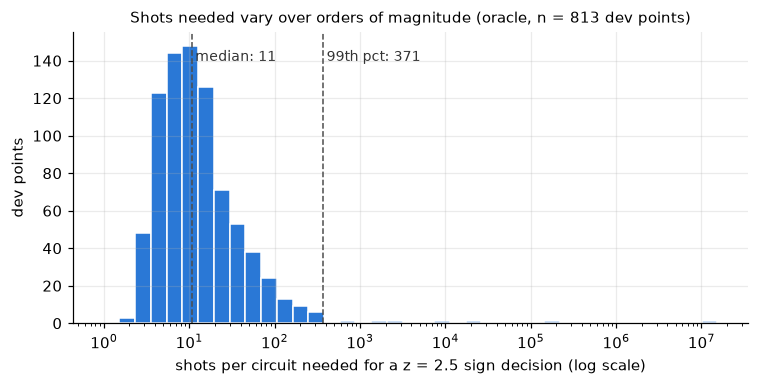

In [5]:
z = 2.5
s_star = z**2 * ((w**2) * K_dev * (1 - K_dev)).sum(axis=1) / f_dev**2
p50, p90, p99 = np.percentile(s_star, [50, 90, 99])
print(f"oracle shots/circuit: median {p50:.0f}, p90 {p90:.0f}, p99 {p99:.0f}, max {s_star.max():.2g}")
print(f"mean if every point got exactly its own s*: {np.minimum(s_star, p99).mean():.0f} (capped at p99)")

fig, ax = plt.subplots(figsize=(7, 3.6))
bins = np.logspace(0, np.log10(s_star.max()) + 0.1, 40)
ax.hist(s_star, bins=bins, color=BLUE, edgecolor="white", linewidth=1)
ax.set_xscale("log")
for v, name in [(p50, "median"), (p99, "99th pct")]:
    ax.axvline(v, color="0.3", linewidth=1, linestyle="--")
    ax.text(v * 1.1, ax.get_ylim()[1] * 0.9, f"{name}: {v:.0f}", color="0.2", fontsize=9)
ax.set_xlabel("shots per circuit needed for a z = 2.5 sign decision (log scale)")
ax.set_ylabel("dev points")
ax.set_title(f"Shots needed vary over orders of magnitude (oracle, n = {len(s_star)} dev points)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "01_oracle_shots.png"); plt.show()

## 4. Simulating shots: fixed baseline vs. adaptive stopping (dev only)

**Shot model.** One shot of the circuit for support vector $i$ returns `00` with probability $k_i$. So the number of `00`s in $s$ shots
is a Binomial$(s, k_i)$ draw. Section 0 of the prep checks confirmed that this matches Qiskit's `StatevectorSampler` (P(00) 0.3985 sampled vs 0.3974 exact).
Drawing binomials with numpy is thousands of times faster than simulating circuits, which is what makes 200 repeated trials possible.

**One draw, every policy.** Shots are drawn in rounds on the schedule 2, 4, 8, …, 2048 shots per circuit, and counts accumulate between rounds.
Every policy reads the *same* random counts (only how many it uses differs). That removes luck as an explanation for differences between policies.

- **Fixed:** every point gets $s$ shots per circuit, for $s$ on the schedule.
- **Adaptive v1:** start at $s_0$. After each round, compute $\hat f$ and its plug-in standard error $\hat\sigma = \sqrt{\sum_i w_i^2 \hat k_i(1-\hat k_i)/s}$.
  Stop when $|\hat f| \ge z\,\hat\sigma$. Otherwise double $s$. At the cap (2048) stop anyway and flag the point as *uncertain*.

**Score.** *Agreement* = fraction of (point, trial) pairs whose predicted sign matches the exact classifier's. *Cost* = mean shots per circuit
(× 20 circuits for shots per prediction). The target is **≥ 99% agreement on dev**.

In [6]:
T = 200                                  # repeated trials (independent shot noise each time)
SCHED = 2 ** np.arange(1, 12)            # 2, 4, ..., 2048 shots per circuit
CAP = SCHED[-1]
rng = np.random.default_rng(7)

def draw_counts(K, rng):
    """Cumulative '00' counts, shape (trials, points, SVs, rounds), for the shot schedule SCHED."""
    incr = np.diff(SCHED, prepend=0)
    draws = [rng.binomial(n, np.broadcast_to(K, (T, *K.shape))) for n in incr]
    return np.cumsum(np.stack(draws, axis=-1), axis=-1).astype(np.int32)

C_dev = draw_counts(K_dev, rng)
khat = C_dev / SCHED                                         # estimated kernel values per round
fhat = np.einsum("tnmr,m->tnr", khat, w) + b                 # estimated decision value per round
sig_plugin = np.sqrt(np.einsum("tnmr,m->tnr", khat * (1 - khat), w**2) / SCHED)
exact_sign = np.sign(f_dev)[None, :]
print("counts array:", C_dev.shape, f"{C_dev.nbytes / 1e6:.0f} MB")

counts array: (200, 813, 20, 11) 143 MB


In [7]:
def fixed_policy(r):
    """Every point uses round r of the schedule."""
    agree = np.sign(fhat[..., r]) == exact_sign
    return dict(agree=agree.mean(), mean_s=SCHED[r], p95_s=SCHED[r], uncertain=np.nan)

def adaptive_policy(sigma, z, r0):
    """Start at round r0; stop at the first round with |fhat| >= z*sigma, or at the cap."""
    ok = np.abs(fhat) >= z * sigma
    ok[..., :r0] = False
    ok[..., -1] = True                                       # the cap always stops
    r_stop = ok.argmax(axis=-1)                              # first True
    f_stop = np.take_along_axis(fhat, r_stop[..., None], -1)[..., 0]
    s_used = SCHED[r_stop]
    certified = np.take_along_axis(np.abs(fhat) >= z * sigma, r_stop[..., None], -1)[..., 0]
    return dict(agree=(np.sign(f_stop) == exact_sign).mean(), mean_s=s_used.mean(),
                p95_s=np.percentile(s_used, 95), uncertain=(~certified).mean(),
                r_stop=r_stop, f_stop=f_stop)

fixed = [fixed_policy(r) for r in range(len(SCHED))]
for s, res in zip(SCHED, fixed):
    print(f"fixed s={s:5d}: agreement {res['agree']:.4f}")

fixed s=    2: agreement 0.8392
fixed s=    4: agreement 0.9018
fixed s=    8: agreement 0.9468
fixed s=   16: agreement 0.9734
fixed s=   32: agreement 0.9870
fixed s=   64: agreement 0.9931
fixed s=  128: agreement 0.9961
fixed s=  256: agreement 0.9972
fixed s=  512: agreement 0.9979
fixed s= 1024: agreement 0.9981
fixed s= 2048: agreement 0.9984


In [8]:
TARGET = 0.99
Z_GRID = [0.5, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5, 4.0, 5.0]
R0_GRID = {4: 1, 8: 2, 16: 3}                                # start shots -> round index
v1 = {(s0, z): adaptive_policy(sig_plugin, z, r0) for s0, r0 in R0_GRID.items() for z in Z_GRID}

print(" s0    z  agreement  mean s  p95 s  uncertain")
for (s0, z), res in v1.items():
    flag = "  <- meets target" if res["agree"] >= TARGET else ""
    print(f"{s0:3d} {z:4.1f}   {res['agree']:.4f}  {res['mean_s']:6.1f}  {res['p95_s']:5.0f}   {res['uncertain']:.4f}{flag}")

# The schedule only has powers of 2, which would flatter adaptive. Fill in the fixed curve between
# them with fresh draws (a separate seed), so the baseline is tuned as finely as adaptive is.
rng_fixed = np.random.default_rng(8)
def fixed_fresh(s):
    k_est = rng_fixed.binomial(s, np.broadcast_to(K_dev, (T, *K_dev.shape))) / s
    return dict(agree=(np.sign(k_est @ w + b) == exact_sign).mean(), mean_s=s)
fixed_curve = sorted([(int(s), r["agree"]) for s, r in zip(SCHED, fixed)]
                     + [(s, fixed_fresh(s)["agree"]) for s in (24, 40, 48, 56, 80, 96)])
best_fixed = next(s for s, a in fixed_curve if a >= TARGET)
meets = {k: r for k, r in v1.items() if r["agree"] >= TARGET}
best_v1 = min(meets, key=lambda k: meets[k]["mean_s"]) if meets else None
print(f"\ncheapest fixed reaching {TARGET:.0%}: {best_fixed} shots/circuit")
print(f"cheapest adaptive v1 reaching {TARGET:.0%}: start {best_v1[0]}, z = {best_v1[1]} -> "
      f"{meets[best_v1]['mean_s']:.1f} shots/circuit on average "
      f"({best_fixed / meets[best_v1]['mean_s']:.1f}x fewer than fixed)")

 s0    z  agreement  mean s  p95 s  uncertain
  4  0.5   0.9424     5.1      8   0.0000
  4  1.0   0.9716     9.4     32   0.0003
  4  1.5   0.9876    19.6     64   0.0018
  4  2.0   0.9947    32.4     64   0.0036  <- meets target
  4  2.5   0.9972    47.2    128   0.0053  <- meets target
  4  3.0   0.9981    63.8    256   0.0064  <- meets target
  4  3.5   0.9983    82.6    256   0.0072  <- meets target
  4  4.0   0.9984   103.4    512   0.0080  <- meets target
  4  5.0   0.9984   150.4    512   0.0092  <- meets target
  8  0.5   0.9714     9.3     16   0.0000
  8  1.0   0.9869    14.1     32   0.0005
  8  1.5   0.9943    24.0     64   0.0020  <- meets target
  8  2.0   0.9972    36.3    128   0.0039  <- meets target
  8  2.5   0.9980    50.1    128   0.0054  <- meets target
  8  3.0   0.9983    65.9    256   0.0065  <- meets target
  8  3.5   0.9984    84.0    256   0.0073  <- meets target
  8  4.0   0.9984   104.2    512   0.0080  <- meets target
  8  5.0   0.9984   150.7    512   0


cheapest fixed reaching 99%: 48 shots/circuit
cheapest adaptive v1 reaching 99%: start 16, z = 1.0 -> 22.2 shots/circuit on average (2.2x fewer than fixed)


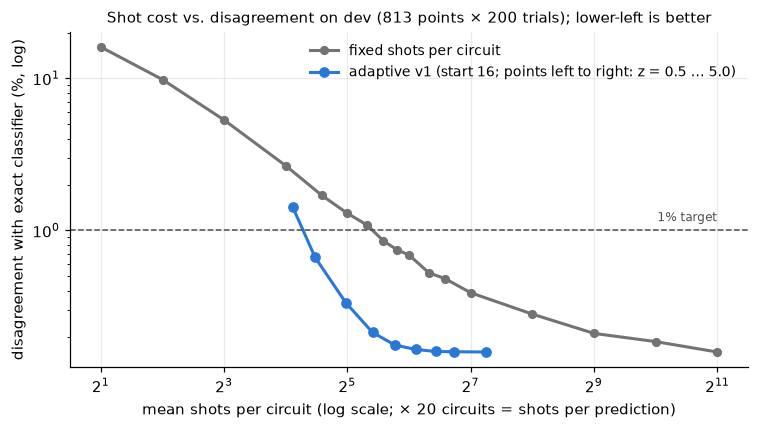

In [9]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(*zip(*[(s, 100 * (1 - a)) for s, a in fixed_curve]), "-o", color="0.45", lw=2, ms=5, label="fixed shots per circuit")
s0_best = best_v1[0] if best_v1 else 8
pts = [v1[(s0_best, z)] for z in Z_GRID]
ax.plot([p["mean_s"] for p in pts], [100 * (1 - p["agree"]) for p in pts], "-o", color=BLUE, lw=2, ms=6,
        label=f"adaptive v1 (start {s0_best}; points left to right: z = {Z_GRID[0]} … {Z_GRID[-1]})")
ax.axhline(100 * (1 - TARGET), color="0.3", lw=1, ls="--")
ax.text(SCHED[-1], 100 * (1 - TARGET) * 1.1, "1% target", fontsize=8, color="0.3", ha="right", va="bottom")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("mean shots per circuit (log scale; × 20 circuits = shots per prediction)")
ax.set_ylabel("disagreement with exact classifier (%, log)")
ax.set_title(f"Shot cost vs. disagreement on dev ({len(X_dev)} points × {T} trials); lower-left is better", fontsize=10)
ax.legend(frameon=False, loc="upper right", fontsize=9)
fig.tight_layout(); fig.savefig(FIG / "02_agreement_vs_cost_dev.png"); plt.show()

## 5. Where does adaptive v1 go wrong? (dev only)

A 99% agreement target averaged over all points is lenient. Most points sit far from the boundary, so almost any rule gets them right,
and all the risk sits in the few points near the boundary. Here we look at v1's wrong predictions directly.

**Near-tie points.** Points whose oracle requirement $s^*$ (section 3, z = 2.5) exceeds the 2048-shot cap can't be settled within the cap by *any* policy.
They're reported separately, as decided in the plan.

In [10]:
near = s_star > CAP
print(f"near-tie dev points (s* > {CAP}): {near.sum()} of {len(near)}")

def per_point_disagreement(f_stop):
    return (np.sign(f_stop) != exact_sign).mean(axis=0)          # per point, over trials

res = v1[best_v1]
d = per_point_disagreement(res["f_stop"])
wrong = np.sign(res["f_stop"]) != exact_sign                     # (trials, points)
r_wrong = res["r_stop"][wrong]
print(f"v1 {best_v1}: overall agreement {res['agree']:.4f}; excluding near-ties {1 - d[~near].mean():.4f}")
print(f"wrong (point, trial) pairs: {wrong.sum()} of {wrong.size}")
print("  stop round of wrong predictions (shots/circuit):",
      {int(SCHED[r]): int((r_wrong == r).sum()) for r in np.unique(r_wrong)})

# Was the plug-in uncertainty collapsing? Count kernel estimates of exactly 0 or 1 at the stopping round.
k_at_stop = np.take_along_axis(khat, res["r_stop"][:, :, None, None], -1)[..., 0]
degenerate = ((k_at_stop == 0) | (k_at_stop == 1)).sum(axis=-1)     # (trials, points): # of SVs with k-hat in {0,1}
print(f"  mean # of SVs with k-hat exactly 0 or 1 at stop: wrong stops {degenerate[wrong].mean():.1f}, "
      f"right stops {degenerate[~wrong].mean():.1f} (of {len(sv)})")

# Disagreement by distance to the boundary.
bins = [0, 0.1, 0.25, 0.5, 1, np.inf]
idx = np.digitize(np.abs(f_dev), bins) - 1
print("\n |f| range      points  mean disagreement  worst point")
for j in range(len(bins) - 1):
    m = idx == j
    if m.any():
        print(f" [{bins[j]:.2f}, {bins[j+1]:.2f})  {m.sum():5d}     {d[m].mean():8.3%}        {d[m].max():6.1%}")
print(f"\nnon-near-tie points wrong in more than 5% of trials: {(d[~near] > 0.05).sum()}")

near-tie dev points (s* > 2048): 5 of 813
v1 (16, 1.0): overall agreement 0.9933; excluding near-ties 0.9958
wrong (point, trial) pairs: 1082 of 162600
  stop round of wrong predictions (shots/circuit): {16: 703, 32: 166, 64: 86, 128: 30, 256: 25, 512: 13, 1024: 10, 2048: 49}
  mean # of SVs with k-hat exactly 0 or 1 at stop: wrong stops 2.6, right stops 2.6 (of 20)

 |f| range      points  mean disagreement  worst point
 [0.00, 0.10)      6      35.833%         51.5%
 [0.10, 0.25)     13       8.615%         14.0%
 [0.25, 0.50)     67       2.500%          7.5%
 [0.50, 1.00)    251       0.181%          3.5%
 [1.00, inf)    476       0.002%          0.5%

non-near-tie points wrong in more than 5% of trials: 21


## 6. Adaptive v2: an uncertainty that can't be zero, and a threshold fixed in advance

Two changes, both motivated by the diagnosis above:

1. **Floored uncertainty.** Estimate each kernel value as $\tilde k_i = (c_i + 1)/(s_i + 2)$ *for the uncertainty only*.
   It's never exactly 0 or 1, so $\hat\sigma$ can't collapse to 0 after a few unlucky shots. The prediction itself still uses $\hat k_i = c_i/s_i$.
2. **Threshold from the error budget, not from tuning.** With $L$ planned checks and an allowed per-point error $\delta$, use
   $z = \Phi^{-1}(1 - \delta/L)$ (a Bonferroni correction: split $\delta$ across the checks). This is still a normal approximation,
   so the measured disagreement is the real test.

**Keep v2 if** it reaches the target at no more cost than v1 does with z simply raised, or if it actually holds its stated per-point error $\delta$ where v1 doesn't.
**Reject it** if raising z in v1 does just as well. That would mean the simple fix was enough.

In [11]:
from scipy.stats import norm

def stop_rule(F, SIG, COST, z, r0=0):
    """Generic adaptive stop: first round >= r0 with |F| >= z*SIG, else the last round.
    F, SIG, COST have shape (trials, points, rounds). Returns a result dict like adaptive_policy."""
    ok = np.abs(F) >= z * SIG
    certified_all = ok.copy()
    ok[..., :r0] = False
    ok[..., -1] = True
    r_stop = ok.argmax(axis=-1)
    pick = lambda A: np.take_along_axis(A, r_stop[..., None], -1)[..., 0]
    f_stop, s_used = pick(F), pick(COST)
    d = per_point_disagreement(f_stop)
    return dict(agree=1 - d.mean(), agree_far=1 - d[~near].mean(), worst_far=d[~near].max(),
                mean_s=s_used.mean(), p95_s=np.percentile(s_used, 95),
                uncertain=(~pick(certified_all)).mean(), r_stop=r_stop, f_stop=f_stop)

COST_UNIFORM = np.broadcast_to(SCHED, fhat.shape)
k_tilde = (C_dev + 1) / (SCHED + 2)
sig_floor = np.sqrt(np.einsum("tnmr,m->tnr", k_tilde * (1 - k_tilde), w**2) / SCHED)

def table(rows):
    print(" policy                     agree   agree(far)  worst far pt  mean s  p95 s  uncertain")
    for name, r in rows:
        print(f" {name:26s} {r['agree']:.4f}   {r['agree_far']:.4f}     {r['worst_far']:6.1%}     {r['mean_s']:6.1f}  {r['p95_s']:5.0f}  {r['uncertain']:.4f}")

v1z = {(s0, z): stop_rule(fhat, sig_plugin, COST_UNIFORM, z, r0) for s0, r0 in R0_GRID.items() for z in Z_GRID}
v2z = {(s0, z): stop_rule(fhat, sig_floor, COST_UNIFORM, z, r0) for s0, r0 in R0_GRID.items() for z in Z_GRID}
cheapest = lambda grid: min((k for k in grid if grid[k]["agree"] >= TARGET), key=lambda k: grid[k]["mean_s"])

rows = [(f"v1 tuned {cheapest(v1z)}", v1z[cheapest(v1z)]), (f"v2 tuned {cheapest(v2z)}", v2z[cheapest(v2z)])]
for delta in (0.05, 0.01):
    for s0, r0 in R0_GRID.items():
        L = len(SCHED) - r0
        z_b = norm.ppf(1 - delta / L)
        rows.append((f"v2 d={delta} s0={s0} (z={z_b:.2f})", stop_rule(fhat, sig_floor, COST_UNIFORM, z_b, r0)))
        rows.append((f"v1 same z s0={s0}", stop_rule(fhat, sig_plugin, COST_UNIFORM, z_b, r0)))
table(rows)

 policy                     agree   agree(far)  worst far pt  mean s  p95 s  uncertain
 v1 tuned (16, 1.0)         0.9933   0.9958      16.5%       22.2     32  0.0006
 v2 tuned (16, 1.0)         0.9939   0.9963      15.0%       22.8     32  0.0006
 v2 d=0.05 s0=4 (z=2.58)    0.9982   0.9999       0.5%       54.8    128  0.0057
 v1 same z s0=4             0.9974   0.9990       2.5%       49.6    128  0.0054
 v2 d=0.05 s0=8 (z=2.54)    0.9983   0.9999       1.0%       54.5    128  0.0056
 v1 same z s0=8             0.9981   0.9998       1.5%       51.3    128  0.0055
 v2 d=0.05 s0=16 (z=2.50)   0.9983   0.9999       0.5%       56.6    128  0.0056
 v1 same z s0=16            0.9982   0.9999       2.0%       54.7    128  0.0055
 v2 d=0.01 s0=4 (z=3.09)    0.9984   1.0000       0.5%       72.2    256  0.0068
 v1 same z s0=4             0.9981   0.9997       1.5%       67.1    256  0.0066
 v2 d=0.01 s0=8 (z=3.06)    0.9984   1.0000       0.5%       71.5    256  0.0067
 v1 same z s0=8       

## 7. Adaptive v3: spend shots where they reduce uncertainty most

So far each round gives every support vector the same number of shots. But the uncertainty of $\hat f$ is $\sum_i w_i^2 k_i(1-k_i)/s_i$,
so a support vector with a small weight, or a kernel value near 0 or 1, contributes little uncertainty however few shots it gets.
For a fixed total, the allocation that minimises the uncertainty is

$$s_i \propto |w_i|\,\sqrt{\tilde k_i(1-\tilde k_i)}$$

(Neyman allocation from survey sampling). AQKA (arXiv 2605.14672) uses a rule of this shape for the *training* kernel matrix; this is its
prediction-time analogue. The per-round budget is the same as v2's, so only *where* the shots go changes. The first round is uniform, since there are no estimates yet.
Fresh shots are drawn here, because each point's allocation depends on its own earlier results.

In [12]:
def run_v3(K, s0_round, rng):
    """Adaptive allocation. Returns F, SIG, COST with shape (trials, points, rounds from s0_round)."""
    M = K.shape[1]
    Kb = np.broadcast_to(K, (T, *K.shape))
    n = np.full((T, *K.shape), SCHED[s0_round])                  # shots so far per SV
    c = rng.binomial(n, Kb)
    F, SIG, COST = [], [], []
    for r in range(s0_round, len(SCHED)):
        if r > s0_round:                                         # allocate this round's budget
            budget = M * (SCHED[r] - SCHED[r - 1])
            kt = (c + 1) / (n + 2)
            score = np.abs(w) * np.sqrt(kt * (1 - kt))
            add = np.maximum(1, np.round(budget * score / score.sum(-1, keepdims=True))).astype(int)
            c = c + rng.binomial(add, Kb); n = n + add
        kt = (c + 1) / (n + 2)
        F.append((c / n) @ w + b)
        SIG.append(np.sqrt((w**2 * kt * (1 - kt) / n).sum(-1)))
        COST.append(n.sum(-1) / M)                               # shots per circuit, averaged over SVs
    return np.stack(F, -1), np.stack(SIG, -1), np.stack(COST, -1)

rng_v3 = np.random.default_rng(9)
v3_runs = {s0: run_v3(K_dev, r0, rng_v3) for s0, r0 in R0_GRID.items()}
v3z = {(s0, z): stop_rule(*v3_runs[s0], z) for s0 in R0_GRID for z in Z_GRID}

rows = [(f"v1 tuned {cheapest(v1z)}", v1z[cheapest(v1z)]),
        (f"v2 tuned {cheapest(v2z)}", v2z[cheapest(v2z)]),
        (f"v3 tuned {cheapest(v3z)}", v3z[cheapest(v3z)])]
for delta in (0.05, 0.01):
    for s0, r0 in R0_GRID.items():
        z_b = norm.ppf(1 - delta / (len(SCHED) - r0))
        rows.append((f"v2 d={delta} s0={s0}", stop_rule(fhat, sig_floor, COST_UNIFORM, z_b, r0)))
        rows.append((f"v3 d={delta} s0={s0}", stop_rule(*v3_runs[s0], z_b)))
table(rows)

 policy                     agree   agree(far)  worst far pt  mean s  p95 s  uncertain
 v1 tuned (16, 1.0)         0.9933   0.9958      16.5%       22.2     32  0.0006
 v2 tuned (16, 1.0)         0.9939   0.9963      15.0%       22.8     32  0.0006
 v3 tuned (4, 1.5)          0.9933   0.9953      10.0%       20.9     64  0.0020
 v2 d=0.05 s0=4             0.9982   0.9999       0.5%       54.8    128  0.0057
 v3 d=0.05 s0=4             0.9983   0.9998       1.0%       48.6    128  0.0054
 v2 d=0.05 s0=8             0.9983   0.9999       1.0%       54.5    128  0.0056
 v3 d=0.05 s0=8             0.9984   1.0000       1.0%       49.2    128  0.0054
 v2 d=0.05 s0=16            0.9983   0.9999       0.5%       56.6    128  0.0056
 v3 d=0.05 s0=16            0.9987   1.0000       1.5%       52.6    128  0.0054
 v2 d=0.01 s0=4             0.9984   1.0000       0.5%       72.2    256  0.0068
 v3 d=0.01 s0=4             0.9985   1.0000       1.0%       63.8    256  0.0064
 v2 d=0.01 s0=8       

## 8. How close are we to the oracle reference?

An **oracle** that knows the exact kernel values can give each point exactly the shots its sign test needs, with no rounds and no estimation error:

- uniform allocation: $s^* = z^2 \sum_i w_i^2 k_i(1-k_i) / f^2$ per circuit (section 3);
- optimal allocation: $s^*_{opt} = z^2 \big(\sum_i |w_i|\sqrt{k_i(1-k_i)}\big)^2 / (M f^2)$ per circuit, averaged over the $M$ circuits.

Both are capped at 2048, like the real policies. **This is an optimistic Gaussian sample-size reference for this estimator (separate kernel circuits,
normal approximation), not a proven lower bound.** Other measurement schemes can beat it. Section 13 does, by measuring the decision value directly.
At low z the real policies can even come in below the oracle, because they then also make more errors, so compare at matched reliability.

In [13]:
M = len(sv)
A_unif = ((w**2) * K_dev * (1 - K_dev)).sum(1) / f_dev**2
A_opt = (np.abs(w) * np.sqrt(K_dev * (1 - K_dev))).sum(1) ** 2 / (M * f_dev**2)
oracle = lambda A, z: np.minimum(z**2 * A, CAP).mean()
print(f"optimal-allocation saving factor per point (uniform / optimal): median {np.median(A_unif / A_opt):.2f}, "
      f"range {np.min(A_unif / A_opt):.2f}-{np.max(A_unif / A_opt):.2f}")
print("\n  z    oracle uniform  oracle optimal   v1 real   v2 real   v3 real   (mean shots/circuit, best start)")
for z in Z_GRID:
    best = lambda grid: min(grid[(s0, z)]["mean_s"] for s0 in R0_GRID)
    print(f" {z:3.1f}   {oracle(A_unif, z):10.1f}   {oracle(A_opt, z):12.1f}   {best(v1z):8.1f}  {best(v2z):8.1f}  {best(v3z):8.1f}")

optimal-allocation saving factor per point (uniform / optimal): median 1.19, range 1.09-1.43

  z    oracle uniform  oracle optimal   v1 real   v2 real   v3 real   (mean shots/circuit, best start)
 0.5          7.7            7.2        5.1       5.5       5.3
 1.0         14.3           13.1        9.4      11.4      10.6
 1.5         20.6           18.7       19.6      23.2      20.9
 2.0         28.8           25.5       32.4      37.1      33.3
 2.5         38.6           34.1       47.2      52.3      46.6
 3.0         49.5           43.5       63.8      69.0      61.0
 3.5         61.9           53.8       82.6      87.5      76.6
 4.0         76.0           65.7      103.4     108.1      93.8
 5.0        108.9           93.3      150.4     154.7     133.8


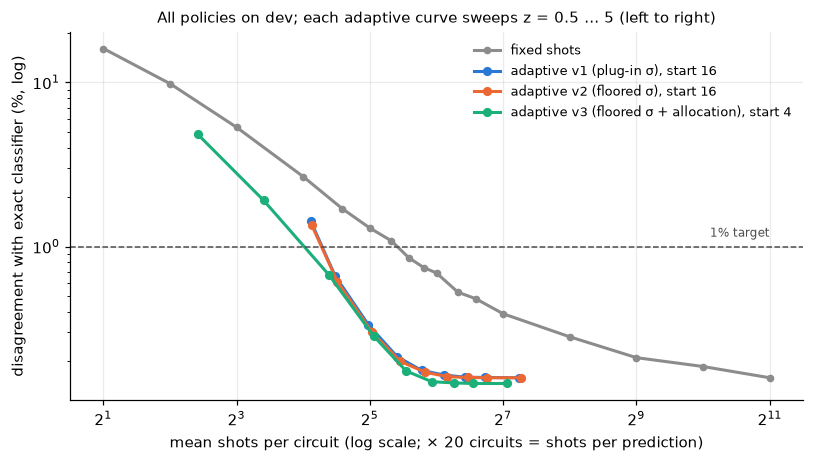

In [14]:
fig, ax = plt.subplots(figsize=(7.5, 4.3))
ax.plot(*zip(*[(s, 100 * (1 - a)) for s, a in fixed_curve]), "-o", color="0.55", lw=2, ms=4, label="fixed shots")
for (name, grid, col) in [("adaptive v1 (plug-in σ)", v1z, BLUE), ("adaptive v2 (floored σ)", v2z, "#eb6834"),
                          ("adaptive v3 (floored σ + allocation)", v3z, "#1baf7a")]:
    s0 = cheapest(grid)[0]
    pts = [grid[(s0, z)] for z in Z_GRID]
    ax.plot([p["mean_s"] for p in pts], [100 * (1 - p["agree"]) for p in pts], "-o", color=col, lw=2, ms=5,
            label=f"{name}, start {s0}")
ax.axhline(100 * (1 - TARGET), color="0.3", lw=1, ls="--")
ax.text(SCHED[-1], 100 * (1 - TARGET) * 1.1, "1% target", fontsize=8, color="0.3", ha="right", va="bottom")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("mean shots per circuit (log scale; × 20 circuits = shots per prediction)")
ax.set_ylabel("disagreement with exact classifier (%, log)")
ax.set_title("All policies on dev; each adaptive curve sweeps z = 0.5 … 5 (left to right)", fontsize=10)
ax.legend(frameon=False, loc="upper right", fontsize=8.5)
fig.tight_layout(); fig.savefig(FIG / "03_all_policies_dev.png"); plt.show()

## 9. A fair baseline for the strict criterion

Section 5 showed that a policy can meet "99% agreement overall" while some individual points are wrong 15% of the time.
The stricter question is: **what does each policy cost if *no* non-near-tie point may be wrong in more than 5% of trials?**
v2 and v3 were built to meet that via $\delta = 0.05$. The fixed policy has to be re-tuned for it too, otherwise the comparison is unfair.

In [15]:
rng_strict = np.random.default_rng(10)
STRICT = 0.05
print(" fixed s   agree   worst non-near-tie point   non-near-tie points wrong > 5%")
fixed_strict = None
for s in (48, 128, 256, 512, 1024, 1280, 1536, 1792, 2048):
    k_est = rng_strict.binomial(s, np.broadcast_to(K_dev, (T, *K_dev.shape))) / s
    d = per_point_disagreement(k_est @ w + b)
    print(f" {s:6d}   {1 - d.mean():.4f}        {d[~near].max():6.1%}                     {(d[~near] > STRICT).sum():3d}")
    if fixed_strict is None and d[~near].max() <= STRICT:
        fixed_strict = s
print(f"\ncheapest fixed meeting the strict criterion: {fixed_strict} shots/circuit")

 fixed s   agree   worst non-near-tie point   non-near-tie points wrong > 5%


     48   0.9916         33.5%                      30


    128   0.9962         25.5%                       4


    256   0.9972         21.0%                       2


    512   0.9977         10.5%                       1


   1024   0.9981          4.0%                       0


   1280   0.9982          3.0%                       0


   1536   0.9983          0.5%                       0


   1792   0.9985          1.5%                       0


   2048   0.9986          0.5%                       0

cheapest fixed meeting the strict criterion: 1024 shots/circuit


## 10. Is there more to gain from a finer schedule?

Doubling overshoots. A point that needs 33 shots gets 64. If the true need is spread evenly on a log scale, doubling wastes about $1/\ln 2 \approx 1.44\times$ on average,
which is roughly the gap between v2 and the oracle in section 8. A finer schedule overshoots less, but it has more checks $L$, so the Bonferroni threshold
$z = \Phi^{-1}(1-\delta/L)$ rises. Cost scales as $z^2$. This cell tests which effect wins (v2-style rule, start 8, $\delta = 0.05$).

In [16]:
rng_g = np.random.default_rng(5)
print(" growth   checks L   z      mean s   agree    worst non-near-tie point")
growth_rows = []
for growth in (2.0, 1.5, 1.25):
    sched = np.unique(np.round(8 * growth ** np.arange(60)).astype(int)); sched = sched[sched <= CAP]
    sched = np.append(sched, CAP) if sched[-1] != CAP else sched
    Kb = np.broadcast_to(K_dev, (T, *K_dev.shape))
    Cg = np.cumsum(np.stack([rng_g.binomial(n, Kb) for n in np.diff(sched, prepend=0)], -1), -1)
    kt = (Cg + 1) / (sched + 2)
    Fg = np.einsum("tnmr,m->tnr", Cg / sched, w) + b
    Sg = np.sqrt(np.einsum("tnmr,m->tnr", kt * (1 - kt), w**2) / sched)
    for z in (norm.ppf(1 - 0.05 / len(sched)), 2.0):
        r = stop_rule(Fg, Sg, np.broadcast_to(sched, Fg.shape), z)
        print(f"  {growth:4.2f}      {len(sched):3d}    {z:4.2f}   {r['mean_s']:6.1f}   {r['agree']:.4f}   {r['worst_far']:6.1%}")
    del Cg, kt

 growth   checks L   z      mean s   agree    worst non-near-tie point


  2.00        9    2.54     54.5   0.9983     1.0%
  2.00        9    2.00     39.0   0.9978     3.0%


  1.50       15    2.71     52.4   0.9984     1.0%
  1.50       15    2.00     33.8   0.9977     6.5%


  1.25       26    2.89     52.2   0.9984     1.0%
  1.25       26    2.00     30.3   0.9975     7.0%


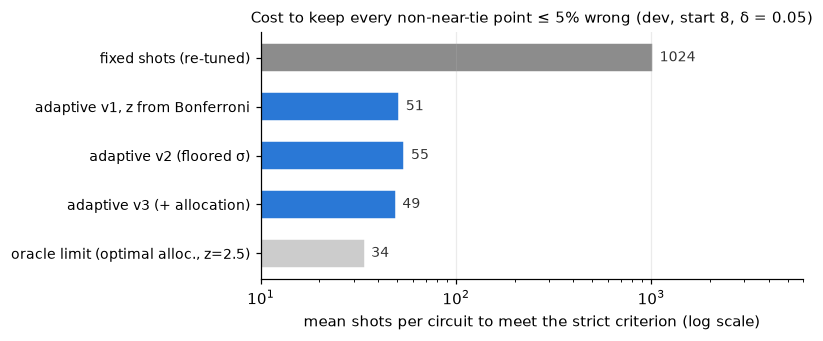

v1: mean 51.3 shots/circuit, worst non-near-tie point 1.5%, 20x fewer than fixed
v2: mean 54.5 shots/circuit, worst non-near-tie point 1.0%, 19x fewer than fixed
v3: mean 49.2 shots/circuit, worst non-near-tie point 1.0%, 21x fewer than fixed


In [17]:
v1_b = stop_rule(fhat, sig_plugin, COST_UNIFORM, norm.ppf(1 - 0.05 / (len(SCHED) - 2)), 2)
v2_b = stop_rule(fhat, sig_floor, COST_UNIFORM, norm.ppf(1 - 0.05 / (len(SCHED) - 2)), 2)
v3_b = stop_rule(*v3_runs[8], norm.ppf(1 - 0.05 / (len(SCHED) - 2)))
bars = [("fixed shots (re-tuned)", fixed_strict, "0.55"),
        ("adaptive v1, z from Bonferroni", v1_b["mean_s"], BLUE),
        ("adaptive v2 (floored σ)", v2_b["mean_s"], BLUE),
        ("adaptive v3 (+ allocation)", v3_b["mean_s"], BLUE),
        ("oracle limit (optimal alloc., z=2.5)", oracle(A_opt, 2.5), "0.80")]
fig, ax = plt.subplots(figsize=(7.5, 3.2))
y = np.arange(len(bars))[::-1]
ax.barh(y, [v for _, v, _ in bars], color=[c for *_, c in bars], height=0.6, edgecolor="white")
for yi, (name, v, _) in zip(y, bars):
    ax.text(v * 1.08, yi, f"{v:.0f}", va="center", fontsize=9, color="0.2")
ax.set_yticks(y, [n for n, *_ in bars], fontsize=9)
ax.set_xscale("log"); ax.set_xlim(10, 6000); ax.grid(axis="y", visible=False)
ax.set_xlabel("mean shots per circuit to meet the strict criterion (log scale)")
ax.set_title("Cost to keep every non-near-tie point ≤ 5% wrong (dev, start 8, δ = 0.05)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "04_strict_criterion_cost_dev.png"); plt.show()
for name, r in [("v1", v1_b), ("v2", v2_b), ("v3", v3_b)]:
    print(f"{name}: mean {r['mean_s']:.1f} shots/circuit, worst non-near-tie point {r['worst_far']:.1%}, "
          f"{fixed_strict / r['mean_s']:.0f}x fewer than fixed")

## 11. Findings on dev from the first pass (sections 4-10)

*(Dev only. Sections 12-13 extend these; held-out test numbers are in section 14, run once.)*

1. **Lenient target (99% agreement averaged over all points).** Fixed needs 48 shots/circuit; tuned adaptive v1 needs about 22. That's about **2.2× fewer**.
   But the tuned threshold (z = 1) is so loose that some individual points are wrong 15–17% of the time. Averaged targets hide this.
2. **Strict target (no non-near-tie point observed wrong in more than 5% of trials).** Fixed must cover the hardest point on *every* point:
   about 1024 shots/circuit (512 fails). Adaptive with a Bonferroni threshold meets it at about 50. That's **~20× fewer**. The two headlines
   answer different questions, so each must be quoted with its target. Caveats: the ratio depends on the predeclared near-tie cutoff (oracle s* > 2048);
   and this is **empirical reliability on this benchmark, not a guarantee**. A per-point rate from 200 trials has 0.5% resolution, and e.g. 8/200 observed (4%) has a
   one-sided 95% Clopper–Pearson upper bound of about 7.1%, so the fixed threshold could plausibly sit anywhere from ~700 to ~1300.
3. **v1's failure was not the zero-uncertainty effect.** Wrong stops had the same number of exactly-0/1 kernel estimates as right stops. They were mostly
   points close to the boundary that stopped in the first round. The floored uncertainty (v2) changed little once the start was ≥ 8 shots.
   **What mattered was the threshold, not the floor.** Raising z in v1 does about as well, so v2's floor is rejected as unnecessary; the Bonferroni threshold is kept.
4. **Smarter allocation (v3) gives ~10%.** That's close to its ceiling *within separate-circuit estimation*: the median uniform/optimal ratio is only 1.19, because the 20 weights
   and kernel values are fairly even.
5. **No further gain among the variants tested here.** Finer schedules gain nothing net (section 10). Bonferroni is conservative, and section 12 replaces it with a calibrated
   Pocock boundary. An earlier draft of this section called the $\sigma^2/f^2$ scaling a hard limit. That was wrong as a general statement: it holds for *this* estimator,
   and section 13's direct measurement lowers $\sigma^2$ itself.
6. **"Zero shots"?** Only by not using the quantum computer: this 2-qubit kernel is cheap to compute exactly on a laptop (that's how the reference is computed).
   Shot cost only matters for kernels that classical computers *can't* compute. That regime is where quantum kernels could be useful at all, and it isn't tested here.

## 12. Parallel workstreams (each independently re-run)

After section 11, the problem was split by cost factor: **cost of a prediction ≈ shots per circuit × circuits per prediction × cost per shot**, plus noise and job overhead.
Each factor was investigated separately with the same dev-only harness and reporting rules. **Every workstream's scripts were re-run and only numbers that
reproduced exactly were kept**. Code and full reports are in `workstreams/`.

| Workstream | Question | Result (dev, simulation) | Decision |
|---|---|---|---|
| W1 stopping rule | A tighter but still principled stopping test? | Pocock group-sequential constant $z=2.419$ (δ=0.05, 9 looks; Pocock 1977, Jennison & Turnbull 2000) + Neyman allocation: **912** shots/prediction vs 1093 for Bonferroni (T=1000), worst non-near point 1.1%. Time-uniform confidence sequences and alpha-spending cost more here (1218–2852). | **Adopt** Pocock + Neyman |
| W2 circuits/prediction | Skip support vectors that can't flip the sign? | No gain: the weights are too even (7 of 20 at the maximum), so the bound never excludes enough. Top-16 SVs saves shots but is a different classifier. | **Reject**; keep all 20 |
| W3 circuit | Compilation, depth, qubit pair | Optimization level 3 → 2.75 two-qubit gates (from 8). Best qubit pair ~2.2× less error than median. reps = 2 best (reps 1/3: 87% / 75% accuracy). | **Adopt** level 3 + best live pair |
| W4 noise | How does hardware noise change predictions? | FakeFez noise is affine: $k_{noisy} \approx 0.888k + 0.028$. Because $\sum_i w_i = 0$ (an SVM dual constraint), the offset cancels and the boundary moves by only ~0.014. Mitigation doesn't change agreement. | Mitigation **not needed** for the sign |
| W5 integrated | All winners together under noise | Baseline 20480 → optimized **698** shots/prediction on the non-near points of the 155-point subset this workstream used (all-point mean 1,859; 2.6% hit the cap; true-label accuracy 98.5% under that noise model vs 99.5% exact), strict criterion met. W3's circuit cuts kernel error 4× and saves ~16% of shots. | Validated |

Two bugs were caught in review: self-similarity calibration circuits $k(x,x)=1$ compile to *zero* gates at optimization level 3 (found in W5 and in an independent
review) and were replaced by known-similarity support-vector pairs; and hardware-run records lacked backend provenance.

## 13. Measuring the decision value directly (one circuit per prediction)

Sections 4-12 estimate 20 separate similarities and add them up classically. But the classifier is linear in the quantum state:

$$f(x) = b + \sum_i w_i \,|\langle\psi(x_i)|\psi(x)\rangle|^2 = b + \langle\psi(x)|\,M\,|\psi(x)\rangle, \qquad M = \sum_i w_i\,|\psi(x_i)\rangle\langle\psi(x_i)|.$$

$M$ is a fixed 4×4 matrix built once from the trained model. Write $M = V\Lambda V^\dagger$. Prepare $|\psi(x)\rangle$, rotate by $V^\dagger$, measure: outcome $j$ scores $\lambda_j$,
and the average score plus $b$ estimates $f(x)$ **for the same classifier**. This construction is prior work (explicit quantum surrogates, Nakayama et al., arXiv:2408.03000), and Gil-Fuster et al. (arXiv:2604.15214)
prove the single-observable route query-optimal with a matching lower bound, so the variance statement below is a finite-shot restatement of their
all-at-once result rather than a new efficiency claim.
The variance argument: $\mathrm{Var}(M) \le \big(\sum_i |w_i|\sqrt{k_i(1-k_i)}\big)^2$ by the triangle inequality, which is exactly the
best (oracle Neyman) separate-circuit variance per shot. So direct measurement is **never worse per *ideal* shot** (equal state-preparation fidelity, rotation treated as free — the compiled direct circuit
carries 3 CZ gates), and better whenever the 20 terms partly cancel.
Limits of that statement: it compares variances, not sign-error probabilities or QPU time; and building $M$ needs the support vectors' states classically, which is cheap
for 2 qubits but does not scale to large, classically hard kernels.

In [18]:
from qiskit.quantum_info import Statevector
psi = lambda x: Statevector(fmap.assign_parameters(x)).data
M_obs = sum(wi * np.outer(psi(xi), psi(xi).conj()) for wi, xi in zip(w, X_sv))
lam, V_obs = np.linalg.eigh(M_obs)
P_dev = np.array([np.abs(V_obs.conj().T @ psi(x)) ** 2 for x in X_dev])     # ideal outcome probabilities
f_direct = b + P_dev @ lam
print("eigenvalues:", lam.round(3), "  trace(M) =", round(float(np.trace(M_obs).real), 12))
print(f"max |f_direct - f_exact| on dev = {np.abs(f_direct - f_dev).max():.1e}, sign disagreements {(np.sign(f_direct) != np.sign(f_dev)).sum()}")
var_direct = P_dev @ lam**2 - (P_dev @ lam) ** 2
var_sep = (np.abs(w) * np.sqrt(K_dev * (1 - K_dev))).sum(1) ** 2
ratio = var_sep / var_direct
print(f"ideal per-shot variance, best separate / direct: median {np.median(ratio):.1f}, min {ratio.min():.1f}, max {ratio.max():.1f}")

eigenvalues: [-2.453 -1.035  1.382  2.106]   trace(M) = 0.0
max |f_direct - f_exact| on dev = 3.8e-15, sign disagreements 0
ideal per-shot variance, best separate / direct: median 13.3, min 6.4, max 153.5


In [19]:
def direct_adaptive(P, T=200, s0=16, looks=9, z=2.419, seed=0):
    """Pocock stopping on direct shots. Total shots per prediction 16, 32, ..., 4096; forced decision at the cap."""
    rng = np.random.default_rng(seed)
    sched = s0 * 2 ** np.arange(looks)
    cnt = np.zeros((T, len(P), 4), np.int64)
    f_stop = np.zeros((T, len(P))); s_stop = np.zeros((T, len(P))); active = np.ones((T, len(P)), bool)
    for l, n in enumerate(sched):
        add = n - (sched[l - 1] if l else 0)
        cnt += np.stack([rng.multinomial(add, p, size=T) for p in P], axis=1)
        pt = (cnt + 0.5) / (n + 2.0)                                       # pseudo-counts keep the variance > 0
        f = b + (cnt / n) @ lam
        sig = np.sqrt((pt @ lam**2 - (pt @ lam) ** 2) / n)
        stop = active & ((np.abs(f) >= z * sig) | (l == looks - 1))
        f_stop[stop] = f[stop]; s_stop[stop] = n; active &= ~stop
    return f_stop, s_stop

fd, sd = direct_adaptive(P_dev)
dd = per_point_disagreement(fd)
print(f"direct + Pocock on dev (noiseless, T={T}): agreement {1 - dd.mean():.4f}, worst non-near point {dd[~near].max():.3f}, "
      f"shots/prediction mean {sd.mean():.1f} (non-near {sd[:, ~near].mean():.1f}), "
      f"dev accuracy {(pred(fd) == y_dev).mean():.4f}")
print(f"for comparison: fixed strict baseline {fixed_strict * len(sv)} shots/prediction; separate Pocock+Neyman ≈ 912 (W1)")

direct + Pocock on dev (noiseless, T=200): agreement 0.9984, worst non-near point 0.045, shots/prediction mean 77.0 (non-near 55.8), dev accuracy 0.9958
for comparison: fixed strict baseline 20480 shots/prediction; separate Pocock+Neyman ≈ 912 (W1)


In [20]:
# Noise check on the same 155-point dev subset W5 used, FakeFez noise model, qubit pair (4,5), opt level 3.
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit_aer import AerSimulator
from qiskit_ibm_runtime.fake_provider import FakeFez

sub = np.load("workstreams/w5_pipeline/probs.npz")["sub"]
fez = FakeFez()
def direct_circuit(x):
    qc = QuantumCircuit(2); qc.compose(fmap.assign_parameters(x), inplace=True)
    qc.append(UnitaryGate(V_obs.conj().T, label="Vdag"), [0, 1]); qc.measure_all()
    return transpile(qc, fez, initial_layout=[4, 5], optimization_level=3, seed_transpiler=7)
dcircs = [direct_circuit(X_dev[i]) for i in sub]
counts = AerSimulator.from_backend(fez, seed_simulator=3).run(dcircs, shots=200_000).result()
P_noisy = np.zeros((len(sub), 4))
for r, c in enumerate(dcircs):
    for key, v in counts.get_counts(c).items():
        P_noisy[r, int(key.replace(" ", ""), 2)] += v / 200_000
f_noisy = b + P_noisy @ lam
slope, offset = np.polyfit(f_dev[sub] - b, f_noisy - b, 1)
print(f"two-qubit gates per direct circuit: {sorted(set(c.count_ops().get('cz', 0) for c in dcircs))}")
print(f"noise: f_noisy - b = {slope:.3f}(f - b) + {offset:.4f}   (offset ~0 because trace(M) = sum(w) = 0)")
for name, Pm in [("noiseless", P_dev[sub]), ("FakeFez noise", P_noisy)]:
    f_s, s_s = direct_adaptive(Pm)
    d_s = (np.sign(f_s) != np.sign(f_dev[sub])[None]).mean(0)
    print(f"direct + Pocock, {name:13s}: agreement {1 - d_s.mean():.4f}, worst non-near {d_s[~near[sub]].max():.3f}, "
          f"shots/prediction non-near mean {s_s[:, ~near[sub]].mean():.1f}")
print("W5 optimized separate-circuit pipeline on the same subset under noise: 698 shots/prediction (non-near)")

two-qubit gates per direct circuit: [3]
noise: f_noisy - b = 0.972(f - b) + 0.0006   (offset ~0 because trace(M) = sum(w) = 0)
direct + Pocock, noiseless    : agreement 0.9924, worst non-near 0.005, shots/prediction non-near mean 54.3
direct + Pocock, FakeFez noise: agreement 0.9915, worst non-near 0.005, shots/prediction non-near mean 58.0
W5 optimized separate-circuit pipeline on the same subset under noise: 698 shots/prediction (non-near)


### 13b. A rigorous alternative: a distribution-free sign certificate

The Pocock rule uses a normal approximation, so its reliability is *empirical*. A rigorous alternative (a noise-aware sign certificate; standard
Hoeffding + union bound): each direct shot is bounded in $[\lambda_{min}, \lambda_{max}]$, range $R$. At the planned looks $n_\ell$, issue a sign only if
$|b + \bar Z_{n_\ell}| > R\sqrt{\log(2L/\delta)/(2n_\ell)}$; otherwise continue, and **abstain** at the cap. For a fixed input, the probability of ever issuing a sign
different from the exact classifier is at most δ, assuming i.i.d. shots and no hardware bias. On hardware, a readout-bias term must be added to the radius; this is not done here.

In [21]:
def certified_direct(P, T=200, s0=16, looks=9, delta=0.05, seed=0):
    rng = np.random.default_rng(seed)
    sched = s0 * 2 ** np.arange(looks); R = lam.max() - lam.min()
    cnt = np.zeros((T, len(P), 4), np.int64); active = np.ones((T, len(P)), bool)
    f_stop = np.zeros((T, len(P))); s_stop = np.full((T, len(P)), sched[-1])
    for l, n in enumerate(sched):
        cnt += np.stack([rng.multinomial(n - (sched[l - 1] if l else 0), p, size=T) for p in P], axis=1)
        fh = b + (cnt / n) @ lam
        stop = active & (np.abs(fh) > R * np.sqrt(np.log(2 * looks / delta) / (2 * n)))
        f_stop[stop] = fh[stop]; s_stop[stop] = n; active &= ~stop
    return f_stop, s_stop, active                                          # active at the end = abstained

fc, sc, abst = certified_direct(P_dev)
wrong = (np.sign(fc) != np.sign(f_dev)[None]) & ~abst
print(f"certified rule on dev (noiseless, T={T}): shots/prediction mean {sc.mean():.0f} (non-near {sc[:, ~near].mean():.0f}); "
      f"abstained {abst.mean():.2%}; wrong certified signs {wrong.sum()} of {(~abst).sum()}")
print(f"empirical Pocock rule on the same data: {sd.mean():.0f} shots/prediction, never abstains, worst non-near point {dd[~near].max():.1%} wrong")

certified rule on dev (noiseless, T=200): shots/prediction mean 203 (non-near 179); abstained 0.81%; wrong certified signs 0 of 161289
empirical Pocock rule on the same data: 77 shots/prediction, never abstains, worst non-near point 4.5% wrong


## 14. Held-out test set (run once, after all design choices were frozen on dev)

Policies, all simulated with ideal shot noise on the 814 test points, T = 200 trials, same seeds and settings as chosen on dev:
fixed 48 (lenient baseline), fixed 1024 (strict baseline), separate-circuit Pocock + Neyman (W1), and direct + Pocock (section 13).
Near-ties on test use the same predeclared rule (oracle $s^* > 2048$), computed from features and the model only, never labels; all-point numbers are shown too.
Reliability is **empirical**: the worst point's rate comes with a one-sided 95% Clopper–Pearson upper bound, which bounds *one* point. Because that point
is selected as the worst of the 813 non-near points, the bound is not a simultaneous statement over the set: the ≤5% criterion here is an empirical
observation on these 814 points, not 95% simultaneous coverage.

In [22]:
import sys
from scipy.stats import beta
sys.path.insert(0, "workstreams/w5_pipeline")
from pipeline import adaptive_predict

K_test = qkernel.evaluate(X_test, X_sv)
f_test = K_test @ w + b
near_t = 2.5**2 * ((w**2) * K_test * (1 - K_test)).sum(1) / f_test**2 > CAP          # z = 2.5, as on dev (the name z was reused in loops above)
P_test = np.array([np.abs(V_obs.conj().T @ psi(x)) ** 2 for x in X_test])
rng_t = np.random.default_rng(2027)
Kt_b = np.broadcast_to(K_test, (T, *K_test.shape))

def fixed_test(s):
    return (rng_t.binomial(s, Kt_b) / s) @ w + b, np.full((T, len(X_test)), s * len(sv))

sep = adaptive_predict(lambda alloc: rng_t.binomial(alloc, Kt_b), w, b, a=1.0, z=2.419, s0=8, looks=9,
                       neyman=True, batch_shape=(T, len(X_test)))
results = {"fixed 48 (lenient baseline)": fixed_test(48), "fixed 1024 (strict baseline)": fixed_test(1024),
           "separate Pocock + Neyman": (sep["f"], sep["shots"]), "direct + Pocock": direct_adaptive(P_test, seed=2028)}

rows = []
for name, (F, Sh) in results.items():
    dis = (np.sign(F) != np.sign(f_test)[None]).mean(0)
    j = np.argmax(np.where(near_t, -1, dis)); k_err = int(round(dis[j] * T))
    ub = beta.ppf(0.95, k_err + 1, T - k_err)
    boot = [Sh[:, idx].mean() for idx in np.random.default_rng(0).integers(0, len(X_test), (500, len(X_test)))]
    rows.append((name, 1 - dis.mean(), dis[~near_t].max(), ub, (pred(F) == y_test).mean(), Sh.mean(),
                 np.percentile(boot, 2.5), np.percentile(boot, 97.5), Sh[:, ~near_t].mean()))
print(f"test points {len(X_test)}, near-ties {near_t.sum()}; exact classifier test accuracy {(pred(f_test) == y_test).mean():.4f}\n")
print(f"{'policy':30s} {'agree':>7s} {'worst':>6s} {'(95% UB)':>8s} {'accuracy':>8s} {'shots/pred':>10s} {'95% CI':>17s} {'non-near':>9s}")
for r in rows:
    print(f"{r[0]:30s} {r[1]:7.4f} {r[2]:6.3f} {r[3]:8.3f} {r[4]:8.4f} {r[5]:10.0f}  [{r[6]:6.0f}, {r[7]:6.0f}] {r[8]:9.0f}")

test points 814, near-ties 1; exact classifier test accuracy 0.9975

policy                           agree  worst (95% UB) accuracy shots/pred            95% CI  non-near
fixed 48 (lenient baseline)     0.9930  0.330    0.389   0.9920        960  [   960,    960]       960
fixed 1024 (strict baseline)    0.9999  0.020    0.045   0.9976      20480  [ 20480,  20480]     20480
separate Pocock + Neyman        0.9999  0.015    0.038   0.9974        781  [   658,    929]       744
direct + Pocock                 0.9998  0.015    0.038   0.9974         65  [    53,     79]        61


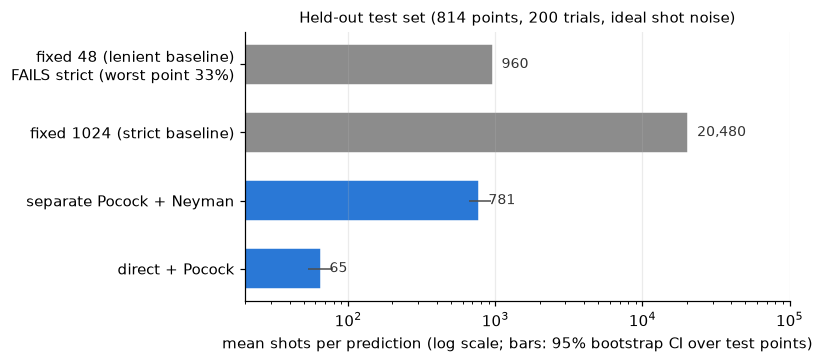

In [23]:
fig, ax = plt.subplots(figsize=(7.5, 3.4))
names = [r[0] + (f"\nFAILS strict (worst point {r[2]:.0%})" if r[2] > STRICT else "") for r in rows][::-1]
vals = [r[5] for r in rows][::-1]
lo = [r[5] - r[6] for r in rows][::-1]; hi = [r[7] - r[5] for r in rows][::-1]
cols = ["0.55" if n.startswith("fixed") else BLUE for n in names]
ax.barh(names, vals, xerr=[lo, hi], color=cols, height=0.6, edgecolor="white", error_kw=dict(ecolor="0.3", lw=1))
for i, v in enumerate(vals):
    ax.text(v * 1.15, i, f"{v:,.0f}", va="center", fontsize=9, color="0.2")
ax.set_xscale("log"); ax.set_xlim(20, 1e5); ax.grid(axis="y", visible=False)
ax.set_xlabel("mean shots per prediction (log scale; bars: 95% bootstrap CI over test points)")
ax.set_title(f"Held-out test set ({len(X_test)} points, {T} trials, ideal shot noise)", fontsize=10)
fig.tight_layout(); fig.savefig(FIG / "05_test_shots_per_prediction.png"); plt.show()

## 15. Real hardware: IBM `ibm_fez` (Heron), 24 October 2026

**Account and budget.** IBM open (free) plan: 10 QPU-minutes per month. This project used **202 billed seconds** (29 timing probe + 173 live A/B).
Code: `hardware/hw_jobs.py` (every job was dry-run on the FakeFez simulator first), `hardware/analyze_live.py`. Raw per-shot results, job ids and billed usage:
`hardware/runs/`. Qubit pair chosen from the **live** calibration by lowest (two-qubit gate + readout) error: (142, 143). Circuits compiled at optimization level 3 (seed 7).

**Design.**
1. *Timing probe* (dev points, no test data): four jobs separating per-job overhead, per-shot cost, per-circuit cost, and the effect of a shorter reset wait between shots
   (`rep_delay` 50 µs vs the 250 µs default).
2. *Live A/B* on 20 test points (15 random + the 5 closest to the boundary that are still decidable within the cap, chosen from the model, never labels).
   **Every policy was executed for real**, so its QPU time is *billed*, not modeled. Each adaptive round is one job, with all undecided points batched.
   The arms change one lever at a time: reset wait (D→E), number of rounds (E→F), adaptive vs a single job (F→G).

| Arm | Circuits | Policy | Reset wait |
|---|---|---|---|
| A `fixed1024` | 20 separate + 5 calibration | 1024 shots each (strict baseline) | 250 µs |
| B `fixed48` | 20 separate | 48 shots each (lenient baseline) | 250 µs |
| D `direct_d2_rd250` | 1 direct | Pocock, doubling 16→4096 (9 rounds) | 250 µs |
| E `direct_d2_rd50` | 1 direct | same | 50 µs |
| F `direct_d4_rd50` | 1 direct | Pocock, ×4 growth 16→4096 (5 rounds) | 50 µs |
| G `direct_fixed2048_rd50` | 1 direct | one job, 2048 shots | 50 µs |

The separate-circuit adaptive policy (W1/W5) was planned as arm C. It was **not run on hardware**: a circuit-indexing bug was found in its live code shortly before submission
(fixed, see section 16), and its re-validation did not finish in time. Its results are simulation-only.

**What the 22× does and does not mean.** It compares arm A (`fixed1024`, the *strict* baseline) with arm G. Every "s per prediction" figure in this
section is a batch average: QPU seconds divided by the 20 inputs decided inside one job, not isolated single-prediction latency and not a rate.
The same run contains a cheaper control that agreed just as well on these twenty inputs — arm B (`fixed48`) at 0.40 s — so the direct arm is 1.6×
faster than fixed 48 *on this batch*. The reason 1024 shots is the strict baseline comes from the 814-point simulation (section 9: fixed 48 leaves a
boundary point wrong 33% of the time), not from these twenty outcomes. And arms A and G differ in three things at once — measurement architecture
(25 circuits → 1), shots per circuit (1024 → 2048) and reset wait (250 → 50 µs) — so the usage improvement **cannot be attributed to the
direct-observable construction alone**.

In [24]:
import json, glob
tim = json.load(open(sorted(glob.glob("hardware/runs/timing-*.json"))[-1]))
print(f"timing probe on {tim['backend']}, qubits {tim['pair']}:")
for j in tim["jobs"]:
    rd = f"{j['rep_delay'] * 1e6:.0f} us" if j["rep_delay"] else "default (250 us)"
    print(f"  {j['tag']:15s} {j['circuits']:4d} circuits x {j['shots']:5d} shots = {j['circuits'] * j['shots']:6d} shots, "
          f"reset wait {rd:16s} billed {j['usage_s']:3.0f} s")
J = {j["tag"]: j for j in tim["jobs"]}
per_shot = (J["t20x2000"]["usage_s"] - J["t20x100"]["usage_s"]) / (40000 - 2000)
per_shot_50 = (J["t20x2000_rd50"]["usage_s"] - J["t20x100"]["usage_s"]) / (40000 - 2000)
print(f"=> about {J['t20x100']['usage_s'] - 2000 * per_shot:.1f} s per job + {per_shot * 1e6:.0f} us per shot (default reset wait), "
      f"{per_shot_50 * 1e6:.0f} us per shot at 50 us; 10x more circuits at equal shots per circuit cost {J['t200x100']['usage_s']} s vs "
      f"{J['t20x100']['usage_s']} s, consistent with shots, not circuits, being the cost. Billing granularity is 1 s, so these are rough.")

timing probe on ibm_fez, qubits [142, 143]:
  t20x100           20 circuits x   100 shots =   2000 shots, reset wait default (250 us) billed   3 s
  t20x2000          20 circuits x  2000 shots =  40000 shots, reset wait default (250 us) billed  13 s
  t200x100         200 circuits x   100 shots =  20000 shots, reset wait default (250 us) billed   8 s
  t20x2000_rd50     20 circuits x  2000 shots =  40000 shots, reset wait 50 us            billed   5 s
=> about 2.5 s per job + 263 us per shot (default reset wait), 53 us per shot at 50 us; 10x more circuits at equal shots per circuit cost 8 s vs 3 s, consistent with shots, not circuits, being the cost. Billing granularity is 1 s, so these are rough.


backend ibm_fez, pair [142, 143], 20 test points (5 near-boundary)
exact classifier on these points: accuracy 0.950
real-chip kernel noise (fixed1024, 400 circuits): k_hw = 0.962 k + 0.0134; mean |k_hw - k| 0.0165; calibration pairs: [0.07  0.157 0.303 0.327 0.483] vs exact [0.075 0.169 0.258 0.364 0.488]
real-chip direct measurement (2048 shots, 50 us): f_hw - b = 0.964(f - b) + -0.0110; mean |f_hw - f| 0.0721

arm                       agree (rand) (hard)    acc  jobs    shots  QPU s QPU s/pred shots/pred
fixed1024                  1.00   1.00   1.00   0.95     1   414720    110       5.50      20736
fixed48                    1.00   1.00   1.00   0.95     1    19200      8       0.40        960
direct_d2_rd250            1.00   1.00   1.00   0.95     9    12880     22       1.10        644
direct_d2_rd50             1.00   1.00   1.00   0.95     9    10896     18       0.90        545
direct_d4_rd50             1.00   1.00   1.00   0.95     5     7616     10       0.50        381
di

saved figures/06_hardware_cost.png


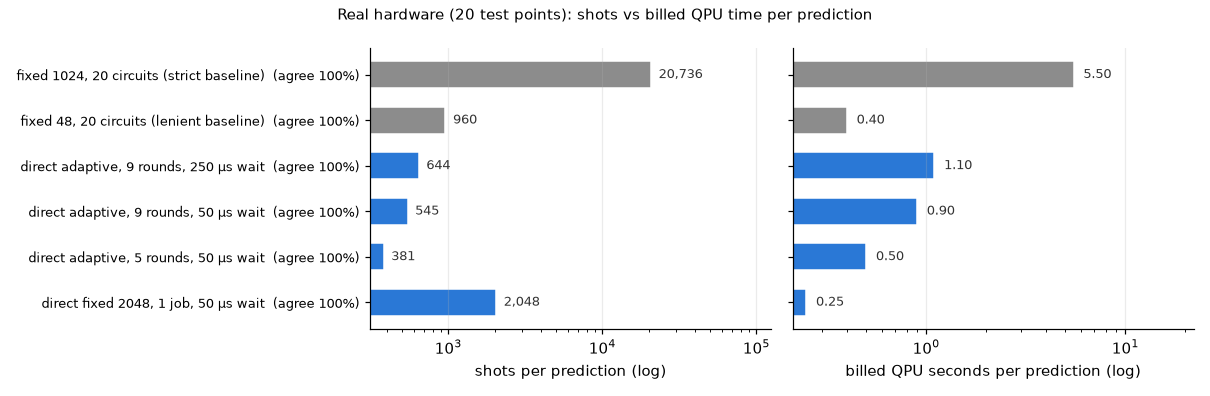

In [25]:
sys.path.insert(0, "hardware")
import analyze_live
analyze_live.main()
from IPython.display import Image
Image("figures/06_hardware_cost.png")

**Reading the hardware results**

- **Agreement.** Every arm predicted the same class as the exact classifier on all 20 points, including the 5 near-boundary ones. This is 20 out of 20, a small sample,
  not a reliability rate; the reliability statistics come from the simulations. Accuracy was 19/20 for every arm, because the exact classifier itself misclassifies one of these points.
- **Noise matched the simulator.** Real kernel values: $k_{hw} \approx 0.962\,k + 0.013$ (FakeFez model predicted ≈ 0.97k). Direct measurement:
  $f_{hw} - b \approx 0.964\,(f-b)$. As analysed in sections 12-13, a uniform squash like this cannot flip a sign except very close to the boundary.
- **Fewest shots ≠ least QPU time.** Every job is billed at least ~2 s. The 5-round adaptive arm used the fewest shots (381/prediction) but 5 jobs (0.50 s/prediction).
  A single 2048-shot job used 5× more shots and **half the time** (0.25 s/prediction, 22× less than the baseline's 5.50 s).
  Adaptive stopping saves *shots*. It only saves *time* when the shots saved per round outweigh the per-job overhead. That happens with larger batches
  of predictions, longer circuits, or slower shots. It doesn't happen here, with 20 points × 2 µs circuits.
- **Shorter reset wait helps**: 1.10 → 0.90 s/prediction (D→E), with a small cost in kernel accuracy in the timing probe
  (mean $|k_{hw}-k|$ 0.0136 vs 0.0104, slope 0.959 vs 0.971).

## 16. Summary: what worked, what didn't, and why

| Idea | Outcome | Why |
|---|---|---|
| Measure only support vectors | **Worked** (2× fewer circuits than measuring all 40 training points, which is what the tutorial kernel does; exact to 2e-15) | Non-support vectors have weight exactly 0 |
| Adaptive stopping (sequential test) | **Worked**: 2.2× (lenient target) / ~20× (strict) fewer shots | The shots each point needs vary over orders of magnitude (∝ 1/f²) |
| Floored variance (v2) | **Rejected** | Diagnosis showed errors came from the threshold, not zero-variance estimates |
| Finer stopping schedule | **No gain** | Less overshoot, but more looks raise the threshold by as much |
| Pocock boundary + Neyman allocation (W1) | **Worked**: 17% fewer shots than Bonferroni, still set in advance | Bonferroni ignores how correlated the nested looks are |
| Lazy SV skipping / pruning (W2) | **Rejected** / trade-off only | Weights too even; pruning changes the classifier |
| Compilation level 3 + best qubit pair (W3) | **Worked**: 2.75 two-qubit gates (from 8), 4× less kernel error, ~16% fewer shots under noise | Two-qubit gates and bad qubits dominate the noise |
| Readout / depolarizing mitigation (W4) | **Not needed for the sign** | $\sum_i w_i = 0$ cancels the noise offset; only a ~0.014 boundary shift remains |
| Self-similarity calibration circuits | **Bug, fixed** | They compile to zero gates, so they would only see readout error. Replaced by known-similarity pairs |
| Direct observable measurement (§13) | **Worked**: 12× fewer shots than the best separate pipeline; 1 circuit instead of 20 | Measures the weighted sum directly; never worse per ideal shot (variance proof) |
| Distribution-free certificate (§13b) | **Works, at ~2.6× the empirical rule's cost**, 0 wrong signs | Trades shots for a real per-point guarantee |
| Hardware: adaptive vs single job | **Single job wins on time** | Per-job billing overhead (~2 s) dominates when circuits are short |

**Corrections made during the project** (kept visible on purpose):
- §8 and §11 first called the oracle a hard limit and Bonferroni an "honest guarantee". Both were overstatements, corrected after review; §13 beat the "limit".
- The first hypothesis for v1's failures (zero-variance collapse) was wrong (§5).
- A hardware-code bug: `np.array(list_of_circuits, dtype=object)` unpacks each Qiskit circuit into its gates, which silently corrupted the separate-adaptive arm's circuit grid.
  It was caught before any QPU time was spent on it, but too late to re-validate and run that arm.
- W1's v2 baseline (1190 shots) differed from section 6's (1090) because of different random draws. It doesn't change any comparison within W1's own runs.

## 17. Limitations, process, and related work

**Limitations**
- A toy problem. A laptop computes this 2-qubit kernel exactly (that's how the reference is computed). Shot cost only matters for classically hard kernels, which aren't tested.
  Building the direct observable needs the support vectors' states classically, which doesn't scale.
- Training is exact (0 shots); only prediction cost is counted.
- One dataset, one classifier, one chip on one day, 20 hardware test points.
- Reliability is empirical (normal-approximation stopping rules) except the §13b certificate, and that one ignores hardware bias.
  Per-point rates from 200 trials have ±~1.5% sampling error near 5%.
- Hardware QPU-time comparisons have 1 s billing granularity.
- The Pocock constant was calibrated for 9 doubling looks; it was also used (conservatively) for the 5-look ×4 schedule.

**Process.** Each change was proposed, implemented, tested on development data, reviewed, and kept or rejected; the frozen methods were then evaluated once on
the held-out test set and on hardware. Workstream scripts (`workstreams/`) were re-run before any number was used.

**Related work**
- Shastry et al., *Shot-frugal and robust quantum kernel classifiers* (ShofaR), arXiv:2210.06971: prediction-time shot budgets vs the exact classifier.
- Xu et al., AQKA, arXiv:2605.14672: adaptive shot allocation for the training kernel matrix.
- Nakayama et al., *Explicit quantum surrogates for quantum kernel models*, arXiv:2408.03000: the direct observable construction.
- Sudipto et al., arXiv:2610.05835: adaptive-shot inference for a variational classifier (close prior art for prediction-time adaptive shots).
- Gil-Fuster et al., arXiv:2604.15214: complexity of inference in quantum kernel methods.
- Pocock (1977); Jennison & Turnbull, *Group Sequential Methods* (2000): the stopping boundary.
- IBM Quantum documentation: job usage and run-time estimation.

No novelty is claimed for adaptive-shot inference or direct observable measurement. The contribution is the combined, measured comparison on this classifier, including real hardware.